In [1]:
# CELL 1 - INSTALL
# Installs the three libraries this notebook needs:
# box2d (the physics engine LunarLander runs on), stable-baselines3 (the PPO
# training library) and imageio (turns pictures into GIFs).
!pip install box2d stable-baselines3 imageio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 20.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [stable-baselines3]stable-baselines3]


In [ ]:
# CELL 2 - IMPORTS AND FOLDERS
# Loads the libraries into Python and creates three folders for our outputs:
# models/ (trained agents), results/ (tables) and media/ (GIFs).
import os, time
import numpy as np, pandas as pd
import gymnasium as gym, imageio
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

MODELS = "/kaggle/working/models"     # trained agents are saved here
RESULTS = "/kaggle/working/results"   # evaluation tables are saved here
MEDIA = "/kaggle/working/media"       # GIFs are saved here
for folder in (MODELS, RESULTS, MEDIA):
    os.makedirs(folder, exist_ok=True)   # create the folder if it doesn't exist

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [3]:
# CELL 3 - PPO SETTINGS
# The training settings (hyperparameters), from the RL Baselines3 Zoo model card
# for LunarLander. The same settings are used for every agent in this project.
HYPERPARAMS = dict(n_steps=1024, batch_size=64, n_epochs=4,
                   gamma=0.999, gae_lambda=0.98, ent_coef=0.01)

In [ ]:
# CELL 4 - TRAINING FUNCTION
# Defines train(): it trains one PPO agent for 1,000,000 steps and saves it.
def train(name, seed, wrapper_class=None, wrapper_kwargs=None, steps=1_000_000):
    # Skip training if this agent is already saved
    if os.path.exists(f"{MODELS}/{name}.zip"):
        print(f"{name}: already trained, skipping")
        return
    start = time.time()
    # Run 16 copies of the game at once; apply the reward wrapper if one is given
    env = make_vec_env("LunarLander-v3", n_envs=16, seed=seed,
                       wrapper_class=wrapper_class, wrapper_kwargs=wrapper_kwargs)
    # Create the PPO agent (a small neural network on CPU)
    model = PPO("MlpPolicy", env, seed=seed, device="cpu", verbose=0, **HYPERPARAMS)
    model.learn(total_timesteps=steps)   # train for 1,000,000 steps
    model.save(f"{MODELS}/{name}")       # save the trained agent
    print(f"{name}: trained in {(time.time()-start)/60:.1f} min")

In [6]:
# CELL 5 - EVALUATION FUNCTION
# Defines evaluate(): it loads a saved agent and plays 100 games with it.
# Scoring uses the ORIGINAL game reward. It records each game's score, length
# and how it ended (landed, crash or timeout), and saves the results as a CSV file.
def evaluate(name, n_episodes=100, first_seed=1000):
    model = PPO.load(f"{MODELS}/{name}", device="cpu")   # load the saved agent
    env = gym.make("LunarLander-v3")        # plain game, original reward
    rows = []
    for i in range(n_episodes):
        # Each game gets its own fixed seed, so every agent faces the same starting conditions
        obs, _ = env.reset(seed=first_seed + i)
        total, steps, over = 0.0, 0, False
        while not over:
            # deterministic=True: the agent always picks its best action
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, _ = env.step(int(action))
            total += reward   # add up the reward for this game
            steps += 1
            over = terminated or truncated   # the game ends on a crash, landing or time limit
        # Work out how the game ended, using the last step's reward
        if truncated:
            outcome = "timeout"    # ran out of time (1000 steps)
        elif reward == -100:
            outcome = "crash"
        elif reward == 100:
            outcome = "landed"
        else:
            outcome = "other"
        rows.append(dict(model=name, episode=i, reward=total, steps=steps, outcome=outcome))
    env.close()
    df = pd.DataFrame(rows)   # one row per game
    df.to_csv(f"{RESULTS}/eval_{name}.csv", index=False)
    return df

In [7]:
# CELL 6 - SUMMARY FUNCTION
# Defines summarize(): it turns the 100-game results from evaluate() into the
# numbers we report: average score, spread, best and worst game, success rate,
# and the share of games that landed, crashed or timed out.
def summarize(df):
    return dict(mean=df["reward"].mean(),                            # average score
                std=df["reward"].std(),                              # how much scores vary
                min=df["reward"].min(),                              # worst game
                max=df["reward"].max(),                              # best game
                success=(df["reward"] >= 200).mean() * 100,          # % of games scoring 200+
                landed=(df["outcome"] == "landed").mean() * 100,     # % that ended in a landing
                crash=(df["outcome"] == "crash").mean() * 100,       # % that ended in a crash
                timeout=(df["outcome"] == "timeout").mean() * 100,   # % that ran out of time
                avg_steps=df["steps"].mean())                        # average game length

In [11]:
# CELL 7 - GIF FUNCTION
# Defines record_gif(): it plays one game with a saved agent, takes a picture
# after every step, and joins the pictures into a GIF in the media/ folder.
def record_gif(name, gif_name, seed=1000):
    model = PPO.load(f"{MODELS}/{name}", device="cpu")
    env = gym.make("LunarLander-v3", render_mode="rgb_array")   # draw pictures into memory
    obs, _ = env.reset(seed=seed)   # fixed seed, so the same game can be replayed
    frames = [env.render()]                      # save the first picture
    over, steps = False, 0
    while not over and steps < 1000:             # stop after 1000 steps at most
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(int(action))
        frames.append(env.render())              # save a picture after every step
        over = terminated or truncated
        steps += 1
    env.close()
    imageio.mimsave(f"{MEDIA}/{gif_name}.gif", frames, fps=30)   # join the pictures into a GIF
    print(f"saved {gif_name}.gif with {len(frames)} frames")

In [ ]:
# CELL 8 - TRAIN THE 5 BASELINE AGENTS
# Trains one agent for each seed from 0 to 4 on the normal game reward.
# Using 5 seeds shows whether the result depends on luck.
for seed in range(5):
    train(f"ppo_baseline_seed{seed}", seed)

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


ppo_baseline_seed0: trained in 17.1 min
ppo_baseline_seed1: trained in 21.8 min
ppo_baseline_seed2: trained in 22.5 min
ppo_baseline_seed3: trained in 20.0 min
ppo_baseline_seed4: trained in 19.5 min


In [13]:
# CELL 9 - BASELINE TABLE
# Plays 100 games with each of the 5 baseline agents, puts their summary numbers
# in one table, and saves it. The last line shows the average of the 5 seed means
# and how much the seed means differ from each other.
rows = []
for seed in range(5):
    df = evaluate(f"ppo_baseline_seed{seed}")              # play 100 games
    rows.append({"model": f"seed{seed}", **summarize(df)}) # keep the summary numbers
table = pd.DataFrame(rows).round(1)
print(table.to_string(index=False))
table.to_csv(f"{RESULTS}/baseline_summary.csv", index=False)
print(f"\nmean of seed means: {table['mean'].mean():.1f} | spread between seeds: {table['mean'].std():.1f}")

model  mean  std   min   max  success  landed  crash  timeout  avg_steps
seed0 260.3 25.9  97.5 306.4     99.0    99.0    0.0      1.0      315.9
seed1 255.2 20.2 209.6 294.0    100.0   100.0    0.0      0.0      365.4
seed2 254.5 20.0 206.9 298.7    100.0   100.0    0.0      0.0      355.9
seed3 267.3 19.6 218.1 308.2    100.0   100.0    0.0      0.0      285.4
seed4 262.3 20.6 214.9 300.1    100.0   100.0    0.0      0.0      303.2

mean of seed means: 259.9 | spread between seeds: 5.3


In [ ]:
# CELL 10 - BEHAVIOUR CHECK (seed 1)
# Defines profile() and runs it on the seed 1 agent. 
def profile(name, n_episodes=30, first_seed=1000):
    model = PPO.load(f"{MODELS}/{name}", device="cpu")
    env = gym.make("LunarLander-v3")
    rows = []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=first_seed + i)
        steps, engine_steps, switches, last_action, over = 0, 0, 0, None, False
        while not over:
            action, _ = model.predict(obs, deterministic=True)
            action = int(action)
            if action != 0:
                engine_steps += 1            # an engine is firing this step
            if last_action is not None and action != last_action:
                switches += 1                # the button changed from last step
            last_action = action
            obs, reward, terminated, truncated, _ = env.step(action)
            steps += 1
            over = terminated or truncated
        # Where the lander ended up and how the game went (obs slots: 0 = x, 1 = y, 3 = y speed, 4 = angle)
        rows.append(dict(final_x=obs[0], final_y=obs[1], steps=steps,
                         engine_steps=engine_steps, switches=switches,
                         final_vy=obs[3], final_angle=obs[4]))
    env.close()
    return pd.DataFrame(rows)   # one row per game

prof = profile("ppo_baseline_seed1")
print(prof.describe().round(2))   # average, spread, min and max of each measure
# The flags are at about x = -0.2 and +0.2, so |x| < 0.2 means it landed between them
print("share landing near the pad (|x| < 0.2):", (prof.final_x.abs() < 0.2).mean())

       final_x  final_y   steps  engine_steps  switches  final_vy  final_angle
count    30.00     30.0   30.00         30.00     30.00      30.0        30.00
mean      0.02     -0.0  368.07        243.23    228.00       0.0         0.00
std       0.04      0.0   25.99         14.97     17.90       0.0         0.00
min      -0.05     -0.0  309.00        215.00    177.00       0.0        -0.01
25%      -0.01     -0.0  351.25        232.75    218.50       0.0        -0.00
50%       0.01     -0.0  365.00        245.50    223.00       0.0         0.00
75%       0.05     -0.0  392.50        253.00    243.25       0.0         0.00
max       0.07      0.0  411.00        267.00    258.00       0.0         0.01
share landing near the pad (|x| < 0.2): 1.0


saved baseline_seed0.gif with 320 frames


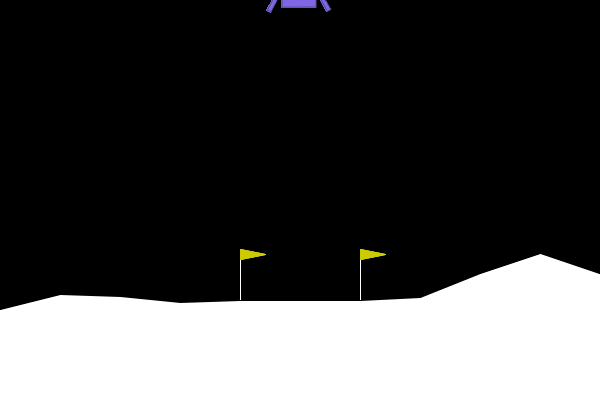

In [15]:
# CELL 11 - BASELINE GIF
# Records one game with the seed 0 agent and shows the GIF in the notebook.
record_gif("ppo_baseline_seed0", "baseline_seed0")
from IPython.display import Image
Image(filename=f"{MEDIA}/baseline_seed0.gif")